# Is the companion's final model better than the chain ladder?

This notebook scores the second tlrn study. The question is simple: does the companion
study's newest model (13 features, a factor head, attention across lines and lags, blended
with the multivariate chain ladder, 20 members averaged) have a lower reserve error than the
chain ladder (`mack`) and the multivariate chain ladder (`mcl`)?

The model was trained on a Colab GPU with `scripts/tlrn_study_colab.py --study factor_head`:
ten independent fits (draws) of each row on each cohort. This notebook only **reads the saved
fits**. It fits the two benchmarks itself, on the cells known at each of four valuation dates,
and runs the evaluator in `scripts/tlrn_study2_eval.py`. The rules for what counts as
`effective` were written down before any fit existed, in
`knowledge/decisions/tlrn-factor-head-study.md`; the evaluator's docstring repeats them. This
notebook does not change them.

Six things to keep in mind while reading:

* **Cohorts A and B are not out-of-sample.** The companion chose its design and its
  hyperparameters with their test data in view, so a verdict on A or B says only whether that
  fixed specification, run many times, beats the benchmarks on the data it was tuned on.
* **Cohort C (accident years 1988 to 1997) is out-of-sample in accident years only.** As far
  as we know the companion did not tune on it (assumed, not known). Its outcomes sit in
  statement years 1998 to 2006, which overlap the data of A and B and the companion's
  valuations 6, 7 and 8, and 67 of its 83 companies are in A and 60 in B (155 of its 232 pairs
  are B's pairs). So it does not test a new economic environment or other companies. Every
  cohort is also selected on future cells existing (a complete 10-by-10 square, outcome cells
  included), a survivorship that applies to the benchmarks as well as the model. Read cohort C
  first: if its verdict is `not distinguishable` or `worse`, the main question is answered
  and A and B are confirmation runs (Amendment 1 of the decision note).
* **The primary verdict cannot detect a small gain.** In the first study the paired 95%
  intervals on A and B were 5.4 to 11.0 points of Pool_APE wide (9.3 to 11.0 against `mack`,
  5.4 to 7.8 against `mcl`; another model, at one date). An interval is wholly below zero
  only if the gain is about half its width, so a gain has to be about three to five points
  to clear both benchmarks. A gain of about half a point, the size of the companion's
  headline gain, cannot be detected (the chance of a clear result would be roughly 4% to
  6%), and `not distinguishable` on A or B is the expected result, not news. The tables
  below print the width of every interval and the gain it could just detect.
* **Amendment 2 changed three rules before any fit** (see the decision note): the second
  condition is a dollar-pooled statistic, not an unweighted mean over the dates; the fourth
  condition no longer passes a model that is behind both benchmarks without the dominant
  company; and a mixed result across cohorts is read mechanically, with cohort C as the
  headline cohort. A stratified bootstrap is shown beside the primary one as a sensitivity
  analysis only.
* **A second question is asked beside the verdict:** does the network add anything beyond the
  blend? It compares the main row with the factors-only row, which share data, factors and
  blend, and it is reported separately; it never changes the verdict.
* **A verdict is provisional** unless the folder holds exactly draws 0 to 9 of the main row.

Every sentence below that states a result is written from the computed values, so it says
nothing until the fits exist.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HERE = Path.cwd().resolve()
REPO = next(p for p in (HERE, *HERE.parents) if (p / "scripts" / "tlrn_study2_eval.py").exists())
sys.path.insert(0, str(REPO / "scripts"))

import tlrn_study2_eval as ev  # noqa: E402
import tlrn_study_colab as study  # noqa: E402

# cohort C first: it is the cohort whose verdict decides the main question
COHORT_ORDER = ("C", "A", "B")

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# Where the saved fits are: the repository's copy of the finished run. Set TLRN_STUDY2_FITS to
# use another folder (for example a new run's study2 folder downloaded from Drive).
FITS_DIR = Path(
    os.environ.get("TLRN_STUDY2_FITS", str(REPO / "analysis" / "results" / "tlrn_study2" / "fits"))
)
# The benchmark fits take a minute or two per cohort; they are kept here and reused.
CACHE_DIR = Path(os.environ.get("TLRN_STUDY2_CACHE", r"C:\Temp\study2_cache"))
# Optional: the companion's rolling table (R_T1_rolling_origin.csv), to tie the benchmarks out.
COMPANION_ROLLING = os.environ.get("TLRN_COMPANION_ROLLING")
# Optional: the companion's member table (T_T1_members.csv), to compare the blend weight and
# the best epoch.
COMPANION_MEMBERS = os.environ.get("TLRN_COMPANION_MEMBERS")
# The first study's fits (analysis/results/tlrn_study/fits in this repository). Without them the accident-year rows are not compared, and the
# output says so.
_first = REPO / "analysis" / "results" / "tlrn_study" / "fits"
FIRST_STUDY_FITS = os.environ.get("TLRN_FIRST_STUDY_FITS") or (
    str(_first) if _first.exists() else None
)

if not FITS_DIR.exists():
    raise SystemExit(
        f"No folder of saved fits at {FITS_DIR}. Copy the Colab run's study2 folder there, or "
        "set TLRN_STUDY2_FITS to its path."
    )

# Read the records: which are this study's, and are they smoke runs?
import json  # noqa: E402

records = {}
for path in sorted(FITS_DIR.glob("*-ibnr*.json")):
    if path.name.startswith("manifest"):
        continue
    info = json.loads(path.read_text(encoding="utf-8"))
    s = info.get("settings", {})
    if s.get("study") == 2 and s.get("study_name") == "factor_head":
        records[path.name] = info
SMOKE = bool(records) and all(r["settings"].get("smoke") for r in records.values())
BANNER = (
    "SMOKE RUN. The fits were a few epochs and a few members. Nothing below may be quoted."
    if SMOKE
    else ""
)
print(f"{len(records)} finished fits of the second study in {FITS_DIR}")
if BANNER:
    print(BANNER)

60 finished fits of the second study in C:\Users\EthanKang\Projects\ibnr-wt\tlrn-study2\analysis\results\tlrn_study2\fits


## 1. What is in the folder

One row per cohort and row: how many draws are saved and which, what they ran on, and how
long a fit took. The registered study is draws 0 to 9 of both rows on each of A, B and C.

In [2]:
rows = []
for cohort_name in COHORT_ORDER:
    for row in ev.ROWS:
        found = [
            r
            for r in records.values()
            if r["settings"]["cohort"] == cohort_name
            and r["settings"]["row"] == row
            and bool(r["settings"].get("smoke")) == SMOKE
        ]
        draws = sorted(r["settings"]["draw"] for r in found)
        seconds = [r["run"].get("fit_seconds") for r in found if r["run"].get("fit_seconds")]
        devices = sorted({str(r["run"].get("device_kind", "?")) for r in found})
        rows.append(
            {
                "cohort": cohort_name,
                "row": row,
                "draws": len(draws),
                "which": ",".join(map(str, draws)) or "none",
                "complete": draws == list(range(10)),
                "device": "; ".join(devices) or "-",
                "median_fit_seconds": float(np.median(seconds)) if seconds else np.nan,
            }
        )
inventory = pd.DataFrame(rows)
inventory

,cohort,row,draws,which,complete,device,median_fit_seconds
0,C,tlrn_13_fh,10,"0,1,2,3,4,5,6,7,8,9",True,NVIDIA RTX PRO 6000 Blackwell Server Edition,177.50
1,C,tlrn_13_fh_factors,10,"0,1,2,3,4,5,6,7,8,9",True,NVIDIA RTX PRO 6000 Blackwell Server Edition,8.60
2,A,tlrn_13_fh,10,"0,1,2,3,4,5,6,7,8,9",True,NVIDIA RTX PRO 6000 Blackwell Server Edition,201.70
3,A,tlrn_13_fh_factors,10,"0,1,2,3,4,5,6,7,8,9",True,NVIDIA RTX PRO 6000 Blackwell Server Edition,9.65
4,B,tlrn_13_fh,10,"0,1,2,3,4,5,6,7,8,9",True,NVIDIA RTX PRO 6000 Blackwell Server Edition,187.80
5,B,tlrn_13_fh_factors,10,"0,1,2,3,4,5,6,7,8,9",True,NVIDIA RTX PRO 6000 Blackwell Server Edition,8.70


## 2. Scoring the fits

For each cohort with fits, the evaluator (`ev.run_cohort`) does four things.

1. It builds the cohort from the cas-schedule-p mart and checks its counts and hash.
2. It fits `mack` (one fit per company-line pair) and `mcl` (one fit per company) with ibnr's
   gallery entries on the cells known at each valuation date, and reads their forecasts cell
   by cell, so they are scored on exactly the cells the transformer is scored on.
3. It checks that each saved fit's tables agree with its own cell sums: the number of cells per
   company and date, the known actuals, and the valuation-10 forecast against the stored
   reserve. A fit that fails is refused by name.
4. It computes the pre-registered statistics.

A valuation date `v` means calendar diagonal `v` of the 10-by-10 square; 10 is the last known
one. At `v` below 10 the cells scored are the later known diagonals at development lag `v` or
less, and the actual is the known paid over them. At 10 the cells are every cell past the last
diagonal and the actual is the realised reserve. The benchmark fits are cached in `CACHE_DIR`.

In [3]:
results, cohorts = {}, {}
cells_ab = None
for cohort_name in COHORT_ORDER:
    if cohort_name in ("A", "B"):
        cells_ab = cells_ab if cells_ab is not None else study.cells_from_mart()
        cells = cells_ab
    else:
        cells = study.cells_from_mart(years=study.YEARS[cohort_name])
    got = ev.run_cohort(
        cohort_name,
        FITS_DIR,
        smoke=SMOKE,
        cells=cells,
        cache_dir=CACHE_DIR,
        companion_rolling=COMPANION_ROLLING,
        companion_members=COMPANION_MEMBERS,
        first_study_dir=FIRST_STUDY_FITS,
    )
    if got is not None:
        cohorts[cohort_name], results[cohort_name] = got
print("\nscored cohorts:", list(results) or "none")

cohort C: 83 companies, 232 pairs, 83 scored; selection [675, 405, 322, 232]; hash 4a613cc4cb5f0f94; data 92f5d7a74f37a0c2; from cas-schedule-p publish 20260613_041006


  benchmarks fitted in 61s; refusals {'mack': 0, 'mcl': 0}
cohort C tlrn_13_fh: data hash differs (fits recorded e52d50e002d50e16, evaluator built 92f5d7a74f37a0c2); anchors, premiums, lines and companies of every fit equal the cohort's within tolerance, so the fits are scored
cohort C tlrn_13_fh_factors: data hash differs (fits recorded e52d50e002d50e16, evaluator built 92f5d7a74f37a0c2); anchors, premiums, lines and companies of every fit equal the cohort's within tolerance, so the fits are scored


cohort A: 93 companies, 243 pairs, 82 scored; selection [668, 414, 330, 243]; hash 08605b3c80513bca; data 13dd7df7e326044a; from cas-schedule-p publish 20260613_041006


  benchmarks fitted in 40s; refusals {'mack': 0, 'mcl': 0}
cohort A tlrn_13_fh: data hash differs (fits recorded 819b8101576f90be, evaluator built 13dd7df7e326044a); anchors, premiums, lines and companies of every fit equal the cohort's within tolerance, so the fits are scored
cohort A tlrn_13_fh_factors: data hash differs (fits recorded 819b8101576f90be, evaluator built 13dd7df7e326044a); anchors, premiums, lines and companies of every fit equal the cohort's within tolerance, so the fits are scored


cohort B: 84 companies, 212 pairs, 84 scored; selection [668, 414, 297, 212]; hash de51bae56cca563c; data 2d9ecc777b088fcd; from cas-schedule-p publish 20260613_041006


  benchmarks fitted in 37s; refusals {'mack': 0, 'mcl': 0}
cohort B tlrn_13_fh: data hash differs (fits recorded bce499efbb6bde4e, evaluator built 2d9ecc777b088fcd); anchors, premiums, lines and companies of every fit equal the cohort's within tolerance, so the fits are scored
cohort B tlrn_13_fh_factors: data hash differs (fits recorded bce499efbb6bde4e, evaluator built 2d9ecc777b088fcd); anchors, premiums, lines and companies of every fit equal the cohort's within tolerance, so the fits are scored



scored cohorts: ['C', 'A', 'B']


## 3. Do the benchmarks and the scoring window tie out?

Before any model number is read, the numbers it is compared with have to be right. The
checks printed here come from the evaluator:

* on cohort A, `mack` and `mcl` must reproduce notebook 04's valuation-10 Pool_APE (the
  evaluator stops if they do not);
* when the companion's rolling table is supplied (`TLRN_COMPANION_ROLLING`), its cell and
  company counts must equal ours at all four dates, and its chain ladder and chain ladder +
  MCL Pool_APE are shown beside `mack` and `mcl`.

In [4]:
for name, res in results.items():
    print(f"=== cohort {name}: {cohorts[name].description}")
    print(f"scored companies: {len(res['companies'])} of the board {len(cohorts[name].board)}")
    if res["left_out"]:
        print("left out because a benchmark failed:", res["left_out"])
    for key, value in res["extras"].items():
        if key == "companion's rolling table":
            continue
        print(f"{key}: {ev.fmt_extra(value)}")
    if "companion_rolling" in res:
        table = res["companion_rolling"]
        display(table.round(6))
        print(
            "largest difference from the companion's Pool_APE:",
            f"mack {table['mack_difference'].abs().max():.1e},",
            f"mcl {table['mcl_difference'].abs().max():.1e}",
        )
    print(
        "cells scored by valuation:",
        {v: res["n_cells_by_valuation"][v] for v in ev.VALUATIONS},
    )
    print()
if not results:
    print("No cohort has finished fits in the folder yet.")

=== cohort C: cohort C: 83 companies, 232 pairs, 83 scored; selection [675, 405, 322, 232]; hash 4a613cc4cb5f0f94; data 92f5d7a74f37a0c2; from cas-schedule-p publish 20260613_041006
scored companies: 83 of the board 83
data hash, tlrn_13_fh: cohort C tlrn_13_fh: data hash differs (fits recorded e52d50e002d50e16, evaluator built 92f5d7a74f37a0c2); anchors, premiums, lines and companies of every fit equal the cohort's within tolerance, so the fits are scored
data hash, tlrn_13_fh_factors: cohort C tlrn_13_fh_factors: data hash differs (fits recorded e52d50e002d50e16, evaluator built 92f5d7a74f37a0c2); anchors, premiums, lines and companies of every fit equal the cohort's within tolerance, so the fits are scored
first study accident-year rows: not applicable: the first study ran cohorts A and B only
cells scored by valuation: {6: 3248, 7: 3480, 8: 3016, 10: 10440}

=== cohort A: cohort A: 93 companies, 243 pairs, 82 scored; selection [668, 414, 330, 243]; hash 08605b3c80513bca; data 13dd7

The rule (with Amendment 2), for the main row `tlrn_13_fh` on each cohort, from the draw
average (every draw's company forecasts averaged, then scored). It is `effective` only if all
four hold:

1. at valuation 10, the Pool_APE difference (model minus benchmark) has a 95% interval wholly
   below zero against both `mack` and `mcl`;
2. the **dollar-pooled** difference over valuations 6, 7, 8 and 10 (the sum of the absolute
   company errors over the sum of the company actuals) has an interval wholly below zero
   against both. The unweighted mean over the four dates is shown as a descriptive only;
3. the median over the draws of the valuation-10 Pool_APE is below both benchmarks';
4. with the dominant company left out, either the valuation-10 difference is at or below zero
   against both benchmarks, or the valuation-10 interval is wholly below zero against both.

It is `worse` if the interval in (1) or (2) is wholly above zero against **either**
benchmark (the first study used the stronger benchmark only), and `not distinguishable`
otherwise. The intervals come from 10,000 resamples of companies, with each company's four
valuation dates kept together. The overall statement follows from the cohort verdicts: cohort
C is the headline cohort for the out-of-sample statement, and A and B confirm a fixed
specification.

In [5]:
table = []
for name, res in results.items():
    row = {
        "cohort": name,
        "what a verdict here means": res["status"],
        "draws": res["n_draws"],
        "verdict": res["verdict_label"],
        "stratified bootstrap says": res["sensitivity_verdict"],
    }
    if res.get("conditions"):
        for key, value in res["conditions"].items():
            row[key] = "yes" if value else "no"
    table.append(row)
verdict_table = pd.DataFrame(table)
display(verdict_table)

for name, res in results.items():
    if res["verdict"] is None:
        print(f"Cohort {name}: there are no finished fits of {ev.MAIN_ROW}, so no verdict is made.")
        continue
    print(f"Cohort {name} ({res['status']}):")
    print(f"  the pre-registered rule gives '{res['verdict_label']}'.")
    print(f"  {res['verdict_reason']}")
    if res["provisional"]:
        print("  This is provisional: the registered study is exactly draws 0 to 9.")
    print()

overall = ev.overall_statement(
    {name: res["verdict"] for name, res in results.items()},
    {name: res["provisional"] for name, res in results.items()},
)
print("Overall statement (Amendment 2):", overall)

,cohort,what a verdict here means,draws,verdict,stratified bootstrap says,i_last_below_both,ii_pooled_below_both,iii_median_draw_below_both,iv_excluding_dominant_not_worse
0,C,out-of-sample in accident years only (not tune...,10,worse,worse,no,no,no,no
1,A,"confirmatory of a fixed specification, not out...",10,not distinguishable,not distinguishable,no,no,yes,no
2,B,"confirmatory of a fixed specification, not out...",10,not distinguishable,not distinguishable,no,no,yes,no


Cohort C (out-of-sample in accident years only (not tuned on as far as we know, assumed not known; its companies and calendar years overlap A and B)):
  the pre-registered rule gives 'worse'.
  vs mack: valuation 10 [-0.0015%, +10.8673%], pooled [+0.0538%, +5.0159%], valuation 10 without the dominant company +4.4681% [-0.9914%, +12.2643%]; vs mcl: valuation 10 [+6.3661%, +12.3242%], pooled [+1.8392%, +4.8068%], valuation 10 without the dominant company +8.1414% [+5.7419%, +11.5200%]; median-draw valuation-10 Pool_APE 15.8857% against mack 11.9470% and mcl 4.9693%; conditions i_last_below_both no, ii_pooled_below_both no, iii_median_draw_below_both no, iv_excluding_dominant_not_worse no

Cohort A (confirmatory of a fixed specification, not out-of-sample):
  the pre-registered rule gives 'not distinguishable'.
  vs mack: valuation 10 [-2.1657%, +2.5779%], pooled [-0.9340%, +2.0711%], valuation 10 without the dominant company +0.0932% [-3.2128%, +3.3891%]; vs mcl: valuation 10 [-5.1431%, 

## 4b. A second question: does the network add anything?

Amendment 1 of the decision note adds one paired question, reported beside the verdict and
never part of it. The main row and the factors-only row (the head's pooled factors with the
blend weight, network off) have the same cohort, companies and draws, and both are blended
with the multivariate chain ladder, so their errors are highly correlated and most of the
company-to-company noise cancels in their difference. The statistic is the Pool_APE of the
draw average, main row minus factors-only row, with the same 10,000-resample bootstrap. The
word is `network adds value` only if the valuation-10 interval and the mean-over-dates
interval are both wholly below zero and, with the dominant company left out, the
valuation-10 interval is not wholly above zero; `network hurts` if either of the first two is
wholly above zero; `not distinguishable` otherwise. Amendment 2 adds one more paired
question, asked the same way: the main row against the raw network (the forecast before the
blend). Its words are `blend adds value`, `blend hurts` and `not distinguishable`. Both
questions are reported beside the verdict and never change it.

In [6]:
net = []
for name, res in results.items():
    row = {
        "cohort": name,
        "network question": res["network_label"],
        "blend question": res["blend_label"],
    }
    for key, value in (res.get("network_conditions") or {}).items():
        row[key] = "yes" if value else "no"
    net.append(row)
display(pd.DataFrame(net))

for name, res in results.items():
    print(f"Cohort {name}: {res['network_reason']}")
    print(f"   blend question: {res['blend_reason']}")
    if len(res["network_check"]):
        display(res["network_check"].round(5))
    print()

,cohort,network question,blend question,a_last_below,b_rolling_below,c_excluding_not_above
0,C,not distinguishable,blend adds value,no,no,yes
1,A,not distinguishable,not distinguishable,no,no,yes
2,B,not distinguishable,not distinguishable,no,no,yes


Cohort C: valuation 10 [-10.0917%, +13.4768%]; rolling [-5.4856%, +6.2104%]; valuation 10 without the dominant company [-11.6605%, +3.3854%]; conditions a_last_below no, b_rolling_below no, c_excluding_not_above yes
   blend question: valuation 10 [-1.5685%, -0.8276%]; rolling [-5.7272%, -0.7218%]; valuation 10 without the dominant company [-1.7679%, -0.7719%]; conditions a_last_below yes, b_rolling_below yes, c_excluding_not_above yes


,model,compared_with,statistic,diff,low,high,share_favour
0,tlrn_13_fh,tlrn_13_fh_factors,last,0.08300,-0.10092,0.13477,0.3390
1,tlrn_13_fh,tlrn_13_fh_factors,rolling,0.04468,-0.05486,0.06210,0.1864
2,tlrn_13_fh,tlrn_13_fh_factors,pooled,0.04870,-0.05619,0.06682,0.1998
3,tlrn_13_fh,tlrn_13_fh_factors,excluding,-0.05240,-0.11660,0.03385,0.9044
4,raw_network,tlrn_13_fh_factors,last,0.09418,-0.08913,0.14647,0.3178
5,raw_network,tlrn_13_fh_factors,rolling,0.06489,-0.01291,0.07945,0.0531
6,raw_network,tlrn_13_fh_factors,excluding,-0.04146,-0.10506,0.04732,0.8521
7,tlrn_13_fh,raw_network,last,-0.01118,-0.01568,-0.00828,1.0000
8,tlrn_13_fh,raw_network,rolling,-0.02021,-0.05727,-0.00722,0.9963
9,tlrn_13_fh,raw_network,pooled,-0.02088,-0.05456,-0.00807,0.9978



Cohort A: valuation 10 [-8.3031%, +2.9022%]; rolling [-5.1493%, +0.6781%]; valuation 10 without the dominant company [-10.2767%, +3.8454%]; conditions a_last_below no, b_rolling_below no, c_excluding_not_above yes
   blend question: valuation 10 [-4.1858%, +0.1024%]; rolling [-3.2144%, -0.4468%]; valuation 10 without the dominant company [-4.7952%, -1.3634%]; conditions a_last_below no, b_rolling_below yes, c_excluding_not_above yes


,model,compared_with,statistic,diff,low,high,share_favour
0,tlrn_13_fh,tlrn_13_fh_factors,last,-0.01645,-0.08303,0.02902,0.8460
1,tlrn_13_fh,tlrn_13_fh_factors,rolling,-0.00304,-0.05149,0.00678,0.6677
2,tlrn_13_fh,tlrn_13_fh_factors,pooled,-0.00364,-0.05418,0.00578,0.7001
3,tlrn_13_fh,tlrn_13_fh_factors,excluding,-0.01184,-0.10277,0.03845,0.6496
4,raw_network,tlrn_13_fh_factors,last,-0.00980,-0.05491,0.05744,0.6751
5,raw_network,tlrn_13_fh_factors,rolling,0.00538,-0.02707,0.01280,0.3359
6,raw_network,tlrn_13_fh_factors,excluding,0.01559,-0.07916,0.06756,0.3698
7,tlrn_13_fh,raw_network,last,-0.00664,-0.04186,0.00102,0.9352
8,tlrn_13_fh,raw_network,rolling,-0.00841,-0.03214,-0.00447,1.0000
9,tlrn_13_fh,raw_network,pooled,-0.00844,-0.03363,-0.00411,1.0000



Cohort B: valuation 10 [-8.5217%, +3.4806%]; rolling [-5.7932%, +0.6233%]; valuation 10 without the dominant company [-10.6151%, +4.3353%]; conditions a_last_below no, b_rolling_below no, c_excluding_not_above yes
   blend question: valuation 10 [-4.7329%, +0.2235%]; rolling [-3.3316%, -0.5088%]; valuation 10 without the dominant company [-5.4460%, -1.1792%]; conditions a_last_below no, b_rolling_below yes, c_excluding_not_above yes


,model,compared_with,statistic,diff,low,high,share_favour
0,tlrn_13_fh,tlrn_13_fh_factors,last,-0.01714,-0.08522,0.03481,0.8304
1,tlrn_13_fh,tlrn_13_fh_factors,rolling,-0.00446,-0.05793,0.00623,0.7148
2,tlrn_13_fh,tlrn_13_fh_factors,pooled,-0.00487,-0.06084,0.00547,0.7406
3,tlrn_13_fh,tlrn_13_fh_factors,excluding,-0.01082,-0.10615,0.04335,0.6310
4,raw_network,tlrn_13_fh_factors,last,-0.01089,-0.06298,0.06959,0.6760
5,raw_network,tlrn_13_fh_factors,rolling,0.00515,-0.03237,0.01315,0.3406
6,raw_network,tlrn_13_fh_factors,excluding,0.01860,-0.08830,0.07988,0.3575
7,tlrn_13_fh,raw_network,last,-0.00625,-0.04733,0.00223,0.8853
8,tlrn_13_fh,raw_network,rolling,-0.00961,-0.03332,-0.00509,1.0000
9,tlrn_13_fh,raw_network,pooled,-0.00946,-0.03498,-0.00459,1.0000


## 5. How much one draw varies

Each dot is the Pool_APE of one draw (one fit of 20 members) of the main row; the cross is the
Pool_APE of the draw average, and the two horizontal marks are `mack` and `mcl`. If the dots
spread across both marks, then a single fit's rank against the benchmarks depends on the
draw, and the draw average is the fairer thing to judge.

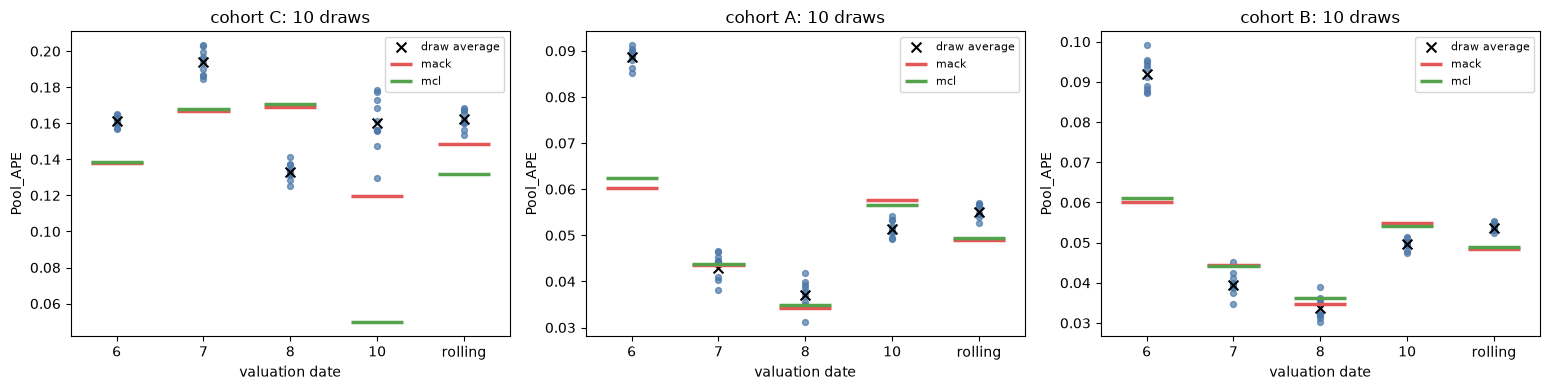

In [7]:
def valuation_labels():
    return [str(v) for v in ev.VALUATIONS] + ["rolling"]


plotted = [n for n, r in results.items() if ev.MAIN_ROW in r["draws"]]
if plotted:
    fig, axes = plt.subplots(1, len(plotted), figsize=(5.2 * len(plotted), 4), squeeze=False)
    for ax, name in zip(axes[0], plotted, strict=True):
        res = results[name]
        draws = res["draw_pool_ape"]
        draws = draws[draws["row"] == ev.MAIN_ROW]
        columns = [f"valuation_{v}" for v in ev.VALUATIONS] + ["rolling"]
        for i, column in enumerate(columns):
            ax.scatter(np.full(len(draws), i), draws[column], s=18, color="#4c78a8", alpha=0.7)
        average = ev.pool_ape_by_valuation(res["series"][ev.MAIN_ROW], res["actual"])
        average = np.append(average, ev.rolling(average))
        ax.scatter(
            range(len(columns)), average, marker="x", color="black", s=50, label="draw average"
        )
        for b, color in (("mack", "#e45756"), ("mcl", "#54a24b")):
            pools = res["benchmark_pool_ape"][b]
            level = np.append(pools, ev.rolling(pools))
            ax.hlines(
                level,
                np.arange(len(columns)) - 0.3,
                np.arange(len(columns)) + 0.3,
                color=color,
                lw=2.5,
                label=b,
            )
        ax.set_xticks(range(len(columns)), valuation_labels())
        ax.set_xlabel("valuation date")
        ax.set_ylabel("Pool_APE")
        ax.set_title(f"cohort {name}: {res['n_draws']} draws" + (" (SMOKE)" if SMOKE else ""))
        ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
else:
    print("No cohort has finished fits of the main row yet.")

## 6. The size of the difference, with intervals

Each point is the Pool_APE of the draw average minus the benchmark's, with its 95% bootstrap
interval. Negative favours the model. The last line of each group is the valuation-10
difference with the dominant company left out. The `pooled` line is the dollar-pooled difference of the verdict rule, and `rolling` the
unweighted mean over the dates (descriptive only). An interval that does not reach zero is
the only kind the verdict rule trusts.

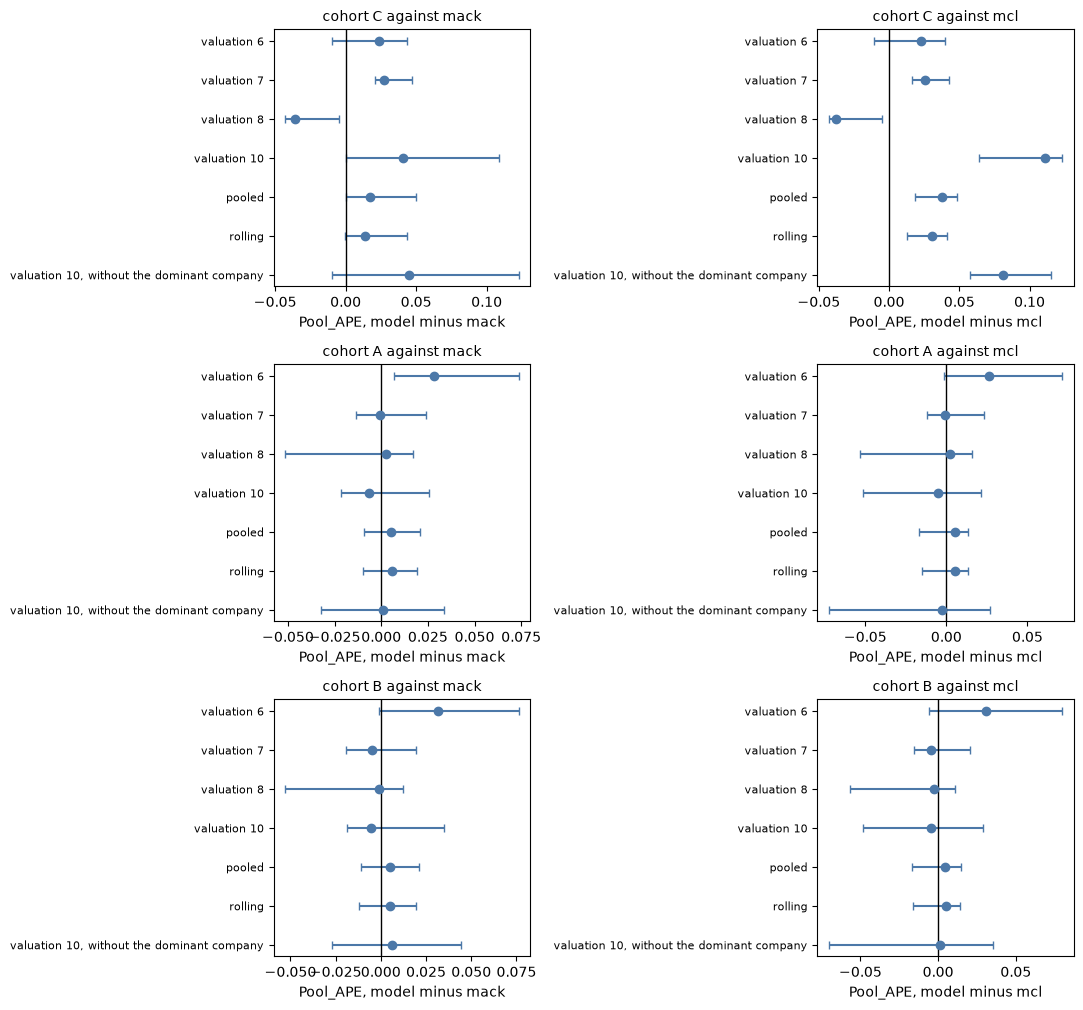

cohort C against mack


,diff,low,high
statistic,,,
valuation 6,0.02336,-0.00993,0.04349
valuation 7,0.02695,0.02050,0.04721
valuation 8,-0.03623,-0.04273,-0.00446
valuation 10,0.04095,-0.00002,0.10867
pooled,0.01705,0.00054,0.05016
rolling,0.01376,-0.00051,0.04333
"valuation 10, without the dominant company",0.04468,-0.00991,0.12264


cohort C against mcl


,diff,low,high
statistic,,,
valuation 6,0.02272,-0.01087,0.03968
valuation 7,0.02580,0.01610,0.04231
valuation 8,-0.03744,-0.04275,-0.00479
valuation 10,0.11072,0.06366,0.12324
pooled,0.03766,0.01839,0.04807
rolling,0.03045,0.01305,0.04155
"valuation 10, without the dominant company",0.08141,0.05742,0.11520


cohort A against mack


...

,diff,low,high
statistic,,,
valuation 6,0.02622,-0.00144,0.07144
valuation 7,-0.00098,-0.01204,0.02311
valuation 8,0.00201,-0.05327,0.01607
valuation 10,-0.00523,-0.05143,0.02136
pooled,0.00505,-0.01667,0.01342
rolling,0.00551,-0.01532,0.01318
"valuation 10, without the dominant company",-0.00257,-0.07237,0.02720


cohort B against mack


,diff,low,high
statistic,,,
valuation 6,0.03183,-0.00080,0.07618
valuation 7,-0.00485,-0.01927,0.01917
valuation 8,-0.00119,-0.05279,0.01225
valuation 10,-0.00519,-0.01873,0.03505
pooled,0.00486,-0.01072,0.02129
rolling,0.00515,-0.01194,0.01948
"valuation 10, without the dominant company",0.00611,-0.02695,0.04406


cohort B against mcl


,diff,low,high
statistic,,,
valuation 6,0.03088,-0.00570,0.07983
valuation 7,-0.00455,-0.01584,0.02046
valuation 8,-0.00247,-0.05691,0.01110
valuation 10,-0.00447,-0.04858,0.02860
pooled,0.00465,-0.01689,0.01458
rolling,0.00485,-0.01626,0.01383
"valuation 10, without the dominant company",0.00113,-0.07021,0.03549


In [8]:
def forest(res, benchmark):
    d = res["differences"]
    d = d[(d["method"] == ev.MAIN_ROW) & (d["benchmark"] == benchmark)].set_index("statistic")
    order = [f"valuation {v}" for v in ev.VALUATIONS] + ["pooled", "rolling"]
    out = d.loc[order, ["diff", "low", "high"]].copy()
    ex = res["excluding_dominant"]
    ex = ex[(ex["method"] == ev.MAIN_ROW) & (ex["benchmark"] == benchmark)].iloc[0]
    out.loc["valuation 10, without the dominant company"] = [ex["diff"], ex["low"], ex["high"]]
    return out


if plotted:
    fig, axes = plt.subplots(len(plotted), 2, figsize=(11, 3.4 * len(plotted)), squeeze=False)
    for r, name in enumerate(plotted):
        for c, b in enumerate(ev.BENCHMARKS):
            ax = axes[r][c]
            data = forest(results[name], b)
            y = np.arange(len(data))[::-1]
            ax.errorbar(
                data["diff"],
                y,
                xerr=[data["diff"] - data["low"], data["high"] - data["diff"]],
                fmt="o",
                color="#4c78a8",
                capsize=3,
            )
            ax.axvline(0, color="black", lw=1)
            ax.set_yticks(y, data.index, fontsize=8)
            ax.set_xlabel("Pool_APE, model minus " + b)
            ax.set_title(f"cohort {name} against {b}" + (" (SMOKE)" if SMOKE else ""), fontsize=10)
    fig.tight_layout()
    plt.show()
    for name in plotted:
        for b in ev.BENCHMARKS:
            print(f"cohort {name} against {b}")
            display(forest(results[name], b).round(5))

## 6b. Precision, and the stratified sensitivity analysis

How wide is each interval, and what is the smallest gain it could have shown? The gain is
about half the width (0.03 is three points of Pool_APE). A gain of half a point is 0.005.
If every width here is several times that, then `not distinguishable` says little about a
small gain.

Next to it, the same differences from a **stratified** bootstrap: the dominant company is in
every resample exactly once and the others are resampled. A uniform resample drops it about
37% of the time. This is a sensitivity analysis. It conditions on that company being present,
so it answers "given this company is in the book, how uncertain is the rest?", it is not the
verdict, and where the two disagree the difference is the finding.

In [9]:
for name, res in results.items():
    if not len(res["precision"]):
        print(f"cohort {name}: no fits of {ev.MAIN_ROW} yet, so no intervals to measure")
        print()
        continue
    print(
        f"cohort {name}: width of each interval for {ev.MAIN_ROW}, and the gain it could just detect"
    )
    cols = ["bootstrap", "benchmark", "statistic", "width", "detectable_gain"]
    display(res["precision"][cols].round(4).reset_index(drop=True))
    print(f"cohort {name}: stratified bootstrap intervals (sensitivity analysis only)")
    display(res["stratified"].round(5))
    print(f"   the same rule on the stratified intervals: {res['sensitivity_verdict']}")
    print()

cohort C: width of each interval for tlrn_13_fh, and the gain it could just detect


,bootstrap,benchmark,statistic,width,detectable_gain
0,uniform,mack,last,0.1087,0.0543
1,uniform,mack,pooled,0.0496,0.0248
2,uniform,mack,rolling,0.0438,0.0219
3,uniform,mcl,last,0.0596,0.0298
4,uniform,mcl,pooled,0.0297,0.0148
5,uniform,mcl,rolling,0.0285,0.0143
6,stratified,mack,last,0.0431,0.0216
7,stratified,mack,pooled,0.0189,0.0094
8,stratified,mack,rolling,0.0169,0.0085
9,stratified,mcl,last,0.0231,0.0116


cohort C: stratified bootstrap intervals (sensitivity analysis only)


,method,benchmark,statistic,diff,low,high,share_favour
0,tlrn_13_fh,mack,last,0.04095,0.01828,0.06142,0.0000
1,tlrn_13_fh,mack,pooled,0.01705,0.00738,0.02625,0.0000
2,tlrn_13_fh,mack,rolling,0.01376,0.00518,0.02212,0.0001
3,tlrn_13_fh,mcl,last,0.11072,0.09976,0.12288,0.0000
4,tlrn_13_fh,mcl,pooled,0.03766,0.03125,0.04450,0.0000
5,tlrn_13_fh,mcl,rolling,0.03045,0.02446,0.03711,0.0000
6,tlrn_13_fh,tlrn_13_fh_factors,last,0.08300,0.04483,0.12607,0.0000
7,tlrn_13_fh,tlrn_13_fh_factors,pooled,0.04870,0.02878,0.06499,0.0000
8,tlrn_13_fh,tlrn_13_fh_factors,rolling,0.04468,0.02471,0.06168,0.0000


   the same rule on the stratified intervals: worse

cohort A: width of each interval for tlrn_13_fh, and the gain it could just detect


...

   the same rule on the stratified intervals: not distinguishable

cohort B: width of each interval for tlrn_13_fh, and the gain it could just detect


,bootstrap,benchmark,statistic,width,detectable_gain
0,uniform,mack,last,0.0538,0.0269
1,uniform,mack,pooled,0.0320,0.0160
2,uniform,mack,rolling,0.0314,0.0157
3,uniform,mcl,last,0.0772,0.0386
4,uniform,mcl,pooled,0.0315,0.0157
5,uniform,mcl,rolling,0.0301,0.0150
6,stratified,mack,last,0.0201,0.0101
7,stratified,mack,pooled,0.0129,0.0064
8,stratified,mack,rolling,0.0130,0.0065
9,stratified,mcl,last,0.0297,0.0149


cohort B: stratified bootstrap intervals (sensitivity analysis only)


,method,benchmark,statistic,diff,low,high,share_favour
0,tlrn_13_fh,mack,last,-0.00519,-0.01486,0.00526,0.8429
1,tlrn_13_fh,mack,pooled,0.00486,-0.00131,0.01154,0.0653
2,tlrn_13_fh,mack,rolling,0.00515,-0.00112,0.01187,0.0569
3,tlrn_13_fh,mcl,last,-0.00447,-0.02068,0.00902,0.7263
4,tlrn_13_fh,mcl,pooled,0.00465,-0.00084,0.01082,0.0507
5,tlrn_13_fh,mcl,rolling,0.00485,-0.00065,0.01111,0.0422
6,tlrn_13_fh,tlrn_13_fh_factors,last,-0.01714,-0.04234,0.00669,0.9126
7,tlrn_13_fh,tlrn_13_fh_factors,pooled,-0.00487,-0.01458,0.00347,0.8300
8,tlrn_13_fh,tlrn_13_fh_factors,rolling,-0.00446,-0.01357,0.00420,0.8041


   the same rule on the stratified intervals: not distinguishable



## 7. With and without the dominant company

In these cohorts one company holds roughly two thirds of the reserve (the next cell prints the exact share), so a Pool_APE that looks
good or bad may be that one company. The table gives the valuation-10 Pool_APE of the
model, the raw network, and both benchmarks with every company and with the dominant one
left out. The companion study reports both versions too.

In [10]:
def pool_without_dominant(res):
    last = ev.VALUATIONS.index(ev.LAST)
    keep = np.array([c != res["dominant_company"] for c in res["companies"]])
    rows = {}
    for method, pred in res["series"].items():
        rows[method] = {
            "all companies": ev.pool_ape(pred[last], res["actual"][last]),
            "without the dominant company": ev.pool_ape(
                pred[last][keep], res["actual"][last][keep]
            ),
        }
    return pd.DataFrame(rows).T


for name, res in results.items():
    print(
        f"cohort {name}: the dominant company is {res['dominant_company']}, with "
        f"{res['dominant_share']:.1%} of the valuation-{ev.LAST} reserve"
    )
    display(pool_without_dominant(res).round(5))

cohort C: the dominant company is 1767, with 66.7% of the valuation-10 reserve


,all companies,without the dominant company
mack,0.11947,0.12323
mcl,0.04969,0.08650
raw_network,0.17159,0.17885
tlrn_13_fh,0.16042,0.16791
tlrn_13_fh_factors,0.07741,0.22031


cohort A: the dominant company is 1767, with 66.3% of the valuation-10 reserve


,all companies,without the dominant company
mack,0.05773,0.12885
mcl,0.05661,0.13236
raw_network,0.05802,0.15722
tlrn_13_fh,0.05138,0.12978
tlrn_13_fh_factors,0.06782,0.14163


cohort B: the dominant company is 1767, with 67.3% of the valuation-10 reserve


,all companies,without the dominant company
mack,0.05481,0.12308
mcl,0.05410,0.12806
raw_network,0.05587,0.15860
tlrn_13_fh,0.04962,0.12919
tlrn_13_fh_factors,0.06676,0.14001


## 8. What the network adds

Three versions of the same forecast, from the same fits: the blended model (the main row),
the raw network before the blend with `mcl`, and the factors-only row (the head's pooled
factors and the blend weight, with the network switched off). If the main row is no better
than the factors-only row, the network is adding nothing beyond the head and the blend. The
last table gives the difference from the main row with its interval (positive means the main
row is better). The pre-registered paired question, with its own rule, is section 4b.

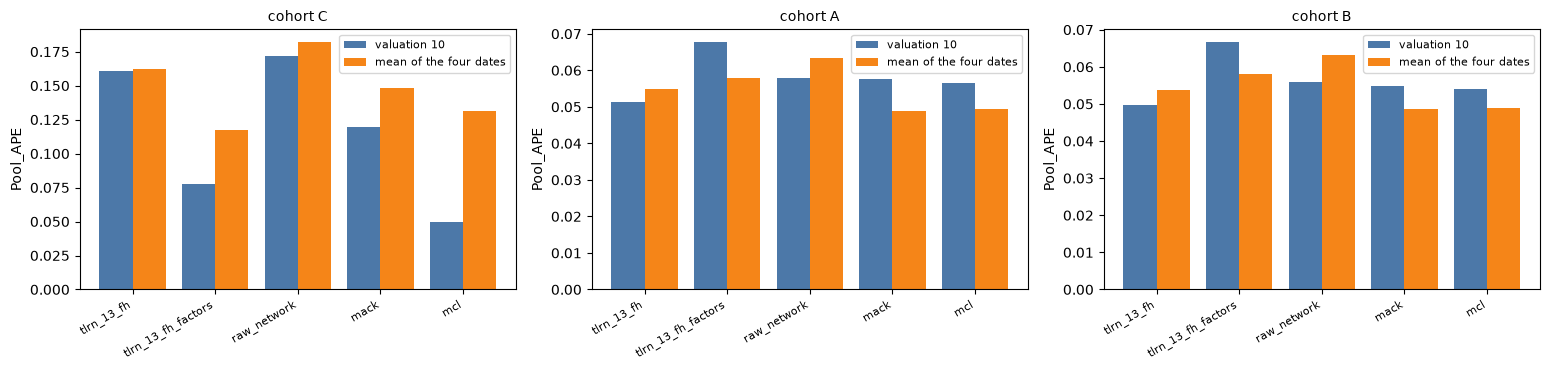

cohort C: each row minus the main row


,row,against,statistic,diff,low,high,share_favour
0,raw_network,tlrn_13_fh,last,0.01118,0.00828,0.01568,0.0000
1,raw_network,tlrn_13_fh,pooled,0.02088,0.00807,0.05456,0.0022
2,raw_network,tlrn_13_fh,rolling,0.02021,0.00722,0.05727,0.0037
3,tlrn_13_fh_factors,tlrn_13_fh,last,-0.08300,-0.13477,0.10092,0.6610
4,tlrn_13_fh_factors,tlrn_13_fh,pooled,-0.04870,-0.06682,0.05619,0.8002
5,tlrn_13_fh_factors,tlrn_13_fh,rolling,-0.04468,-0.06210,0.05486,0.8136


cohort A: each row minus the main row


,row,against,statistic,diff,low,high,share_favour
0,raw_network,tlrn_13_fh,last,0.00664,-0.00102,0.04186,0.0648
1,raw_network,tlrn_13_fh,pooled,0.00844,0.00411,0.03363,0.0000
2,raw_network,tlrn_13_fh,rolling,0.00841,0.00447,0.03214,0.0000
3,tlrn_13_fh_factors,tlrn_13_fh,last,0.01645,-0.02902,0.08303,0.1540
4,tlrn_13_fh_factors,tlrn_13_fh,pooled,0.00364,-0.00578,0.05418,0.2999
5,tlrn_13_fh_factors,tlrn_13_fh,rolling,0.00304,-0.00678,0.05149,0.3323
6,first_study:tlrn_8_ay,tlrn_13_fh,last,0.00627,-0.03665,0.04635,0.3022
7,first_study:tlrn_13_ay,tlrn_13_fh,last,0.01098,-0.04411,0.02758,0.3292


cohort B: each row minus the main row


,row,against,statistic,diff,low,high,share_favour
0,raw_network,tlrn_13_fh,last,0.00625,-0.00223,0.04733,0.1147
1,raw_network,tlrn_13_fh,pooled,0.00946,0.00459,0.03498,0.0000
2,raw_network,tlrn_13_fh,rolling,0.00961,0.00509,0.03332,0.0000
3,tlrn_13_fh_factors,tlrn_13_fh,last,0.01714,-0.03481,0.08522,0.1696
4,tlrn_13_fh_factors,tlrn_13_fh,pooled,0.00487,-0.00547,0.06084,0.2594
5,tlrn_13_fh_factors,tlrn_13_fh,rolling,0.00446,-0.00623,0.05793,0.2852
6,first_study:tlrn_8_ay,tlrn_13_fh,last,0.00815,-0.04736,0.03637,0.3242
7,first_study:tlrn_13_ay,tlrn_13_fh,last,0.00660,-0.05824,0.02514,0.4027


In [11]:
order = [ev.MAIN_ROW, ev.FACTORS_ROW, ev.RAW_NETWORK, "mack", "mcl"]
if results:
    fig, axes = plt.subplots(1, len(results), figsize=(5.2 * len(results), 3.8), squeeze=False)
    for ax, (name, res) in zip(axes[0], results.items(), strict=True):
        present = [m for m in order if m in res["series"]]
        last = ev.VALUATIONS.index(ev.LAST)
        v10 = [ev.pool_ape(res["series"][m][last], res["actual"][last]) for m in present]
        roll = [
            ev.rolling(ev.pool_ape_by_valuation(res["series"][m], res["actual"])) for m in present
        ]
        x = np.arange(len(present))
        ax.bar(x - 0.2, v10, 0.4, label="valuation 10", color="#4c78a8")
        ax.bar(x + 0.2, roll, 0.4, label="mean of the four dates", color="#f58518")
        ax.set_xticks(x, present, rotation=30, ha="right", fontsize=8)
        ax.set_ylabel("Pool_APE")
        ax.set_title(f"cohort {name}" + (" (SMOKE)" if SMOKE else ""), fontsize=10)
        ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
    for name, res in results.items():
        print(f"cohort {name}: each row minus the main row")
        display(
            res["comparison_rows"].round(5)
            if len(res["comparison_rows"])
            else "no comparison rows yet"
        )

## 9. The other metrics

Reported beside the verdict, not part of it. `pool_pe` is the bias (sum of errors over sum
of actuals); `medape` the median absolute percentage error; `mae` the mean absolute error;
`log_ratio` the mean absolute log of predicted over actual reserve, over companies where both
are positive; `share_better_than_*` the share of companies where the row's absolute error is
smaller than the benchmark's. The mean absolute percentage error (`mape`) and the
reserve-weighted RMSE (`wrmse`) are **descriptive only**: they are driven by very small
reserves and by one large company, which is where the companion's claimed gains are largest.

In [12]:
for name, res in results.items():
    m = res["metrics"]
    m = m[m["valuation"].isin(["10", "rolling"])]
    print(f"cohort {name}: reported metrics")
    display(
        m[
            [
                "method",
                "valuation",
                "pool_ape",
                "pool_pe",
                "medape",
                "mae",
                "log_ratio",
                "share_better_than_mack",
                "share_better_than_mcl",
            ]
        ]
        .round(5)
        .reset_index(drop=True)
    )
    print(f"cohort {name}: descriptive only")
    display(m[["method", "valuation", "mape", "wrmse"]].round(5).reset_index(drop=True))

cohort C: reported metrics


,method,valuation,pool_ape,pool_pe,medape,mae,log_ratio,share_better_than_mack,share_better_than_mcl
0,mack,10,0.11947,0.11329,0.15402,28048.20227,0.19984,NaN,0.59036
1,mack,rolling,0.14836,0.13490,0.13362,28057.49729,0.18238,NaN,0.37651
2,mcl,10,0.04969,0.03792,0.16878,11666.57142,0.22786,0.39759,NaN
3,mcl,rolling,0.13167,0.11494,0.13561,24094.60909,0.18817,0.32831,NaN
4,raw_network,10,0.17159,0.17105,0.29498,40285.37888,0.29605,0.26506,0.27711
5,raw_network,rolling,0.18233,0.17274,0.21438,35352.82281,0.23440,0.36145,0.35843
6,tlrn_13_fh,10,0.16042,0.15977,0.28389,37661.42839,0.28568,0.26506,0.28916
7,tlrn_13_fh,rolling,0.16212,0.15247,0.16894,31336.79828,0.19743,0.43373,0.44578
8,tlrn_13_fh_factors,10,0.07741,-0.00686,0.26235,18174.35906,0.29077,0.39759,0.40964
9,tlrn_13_fh_factors,rolling,0.11744,0.07005,0.16332,21969.47836,0.21679,0.45783,0.45181


cohort C: descriptive only


,method,valuation,mape,wrmse
0,mack,10,0.25035,1.251416e+06
1,mack,rolling,0.21330,1.259558e+06
2,mcl,10,0.32398,3.333561e+05
3,mcl,rolling,0.23192,1.030232e+06
4,raw_network,10,0.37864,1.785266e+06
5,raw_network,rolling,0.27779,1.561470e+06
6,tlrn_13_fh,10,0.36714,1.665213e+06
7,tlrn_13_fh,rolling,0.23383,1.394644e+06
8,tlrn_13_fh_factors,10,0.41923,1.225636e+05
9,tlrn_13_fh_factors,rolling,0.26064,7.630525e+05


cohort A: reported metrics


...

,method,valuation,mape,wrmse
0,mack,10,1.15346,298622.49402
1,mack,rolling,0.57311,296630.74197
2,mcl,10,0.91794,240698.43172
3,mcl,rolling,0.56507,282255.70572
4,raw_network,10,0.37287,167237.14313
5,raw_network,rolling,0.34951,395129.30777
6,tlrn_13_fh,10,0.53433,185748.96136
7,tlrn_13_fh,rolling,0.39936,364560.09873
8,tlrn_13_fh_factors,10,0.80361,381459.92968
9,tlrn_13_fh_factors,rolling,0.48641,266604.67206


cohort B: reported metrics


,method,valuation,pool_ape,pool_pe,medape,mae,log_ratio,share_better_than_mack,share_better_than_mcl
0,mack,10,0.05481,0.00730,0.13417,14753.78105,0.28893,NaN,0.53571
1,mack,rolling,0.04854,0.01723,0.13548,10876.83820,0.25140,NaN,0.44048
2,mcl,10,0.05410,-0.00468,0.17827,14562.20394,0.27767,0.46429,NaN
3,mcl,rolling,0.04884,0.01450,0.14696,10922.74095,0.26090,0.36905,NaN
4,raw_network,10,0.05587,0.04018,0.18284,15039.02372,0.24659,0.46429,0.48810
5,raw_network,rolling,0.06329,0.02530,0.17908,14023.88011,0.23493,0.46131,0.47321
6,tlrn_13_fh,10,0.04962,0.02253,0.13278,13357.85702,0.23912,0.55952,0.53571
7,tlrn_13_fh,rolling,0.05369,0.02264,0.14902,11945.21334,0.21939,0.55060,0.56548
8,tlrn_13_fh_factors,10,0.06676,-0.02597,0.19608,17970.94844,0.28011,0.48810,0.52381
9,tlrn_13_fh_factors,rolling,0.05815,-0.01710,0.16087,13016.50881,0.25467,0.47321,0.49405


cohort B: descriptive only


,method,valuation,mape,wrmse
0,mack,10,1.14061,300307.77804
1,mack,rolling,0.56842,298513.28213
2,mcl,10,0.90950,242025.54032
3,mcl,rolling,0.55661,284043.34992
4,raw_network,10,0.36756,158477.95995
5,raw_network,rolling,0.35127,400133.27320
6,tlrn_13_fh,10,0.53518,180981.02938
7,tlrn_13_fh,rolling,0.39860,363341.44940
8,tlrn_13_fh_factors,10,0.79706,393991.54930
9,tlrn_13_fh_factors,rolling,0.48351,266973.26910


## 10. By size of reserve, and the blend weight

Pool_APE within quartiles of the actual reserve at valuation 10 (quartile 4 holds the
largest reserves, and the dominant company), then the median blend weight `alpha` over all
members and draws at each valuation date. The companion's published median `alpha` is around
0.63 at valuation 10.

In [13]:
for name, res in results.items():
    q = res["quartiles"]
    q = q[q["valuation"] == ev.LAST]
    print(f"cohort {name}: Pool_APE by quartile of actual reserve, valuation {ev.LAST}")
    display(q.pivot_table(index=["quartile", "n"], columns="method", values="pool_ape").round(4))
    if "alpha" in res:
        print(f"cohort {name}: median blend weight")
        display(res["alpha"].round(4))
        print(f"cohort {name}: spread of the blend weight (all members of all draws)")
        display(res["alpha_spread"].round(4))
    if "members_fidelity" in res:
        print(f"cohort {name}: against the companion's published member table")
        display(res["members_fidelity"].round(4))

cohort C: Pool_APE by quartile of actual reserve, valuation 10


,method,mack,mcl,raw_network,tlrn_13_fh,tlrn_13_fh_factors
quartile,n,,,,,
1,21,0.3057,0.3757,0.5451,0.5213,0.4475
2,21,0.1766,0.1997,0.3059,0.2913,0.2476
3,21,0.1619,0.2037,0.3439,0.3211,0.2958
4,20,0.1169,0.0420,0.1634,0.1526,0.0673


cohort C: median blend weight


,valuation,alpha_median
0,6,0.3466
1,7,0.4805
2,8,0.6782
3,10,0.9361


cohort C: spread of the blend weight (all members of all draws)


...

,method,mack,mcl,raw_network,tlrn_13_fh,tlrn_13_fh_factors
quartile,n,,,,,
1,21,2.4308,1.9760,0.5739,1.1046,1.6849
2,21,0.2523,0.2495,0.2318,0.2015,0.2404
3,21,0.2023,0.2742,0.1915,0.1541,0.2222
4,21,0.0437,0.0410,0.0482,0.0425,0.0567


cohort B: median blend weight


,valuation,alpha_median
0,6,0.6089
1,7,0.8135
2,8,0.7128
3,10,0.6079


cohort B: spread of the blend weight (all members of all draws)


,valuation,alpha_min,alpha_q25,alpha_median,alpha_q75,alpha_max,alpha_std,alpha_count
0,6,0.2715,0.4959,0.6089,0.7638,1.0000,0.1828,200
1,7,0.2423,0.6630,0.8135,0.9334,1.0000,0.1774,200
2,8,0.2866,0.5967,0.7128,0.8188,1.0000,0.1663,200
3,10,0.3948,0.5393,0.6079,0.6814,0.8736,0.0983,200


## What this cannot show

* The companion's design was tuned on A and B. Cohort C is independent in accident years but
  not in calendar time (its outcomes sit in statement years 1998 to 2006, overlapping A and B
  and the companion's valuations 6, 7 and 8) and not in companies (67 of its 83 companies are
  in A, 60 in B). Whether the companion tuned on C is not known: it is assumed it did not. So
  C does not test a new economic environment or other companies.
* Every cohort is selected on future cells existing, which is a shared survivorship: it applies
  to the benchmarks as well as the model.
* The primary verdict on one cohort can detect a gain of about three to five points of Pool_APE
  and not a half-point gain, so `not distinguishable` is the expected result.
* The bootstrap resamples companies. It measures company-to-company sampling and says
  nothing about other years beyond what cohort C adds.
* Ten draws sample training randomness thinly, and a GPU rerun gives different draws.
* The model blends the multivariate chain ladder into every member (the weight is fitted),
  so it is partly the benchmark it is compared with.
* Three cohorts are judged and no multiplicity correction is made.